# Chapter 10: Sketches and Estimators

Companion notebook for **Chapter 10** of *Bernoulli Types: An Algebra of Approximate Computation*. Source files: `book/chapters/ch10/`.

Chapter 10 builds three canonical sketches from scratch and casts each as a $\Bernoulli{T}$ instance under the chapter 9 framework:

1. **CountMin** (§10.2) is an approximate frequency counter $\Bernoulli{\mathbb{N}}$. Always over-estimates (one-sided like Bloom). Parameters: width $w$, depth $d$, error parameter $\epsilon$, failure probability $\delta$.
2. **HyperLogLog** (§10.3) is an approximate cardinality estimator $\Bernoulli{\mathbb{N}}$. Two-sided error, log-log space in the cardinality. Parameter: register count $m$.
3. **MinHash** (§10.4) is an approximate Jaccard-similarity estimator $\Bernoulli{[0, 1]}$. Two-sided, symmetric error. Parameter: signature length $k$.

This notebook implements each sketch from scratch (no external sketch libraries), checks its error bound empirically against the theoretical guarantee, and verifies the composition operation (`merge`) where applicable. The closing summary table reports storage cost and accuracy on a common workload, setting up the chapter 13 type-algebra unification.

**Conventions:**
- Hash family: per-row SHA-256 with a deterministic salt derived from `(seed, row_index)`. Output is reduced into the relevant range (`mod w`, top-$p$ bits, etc.) per sketch.
- All randomness is seeded for reproducibility (the same notebook always produces the same numbers).
- $k$ in this notebook is the MinHash signature length, not the chapter 5 Bloom hash count.

In [1]:
import hashlib
import math
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

rng = np.random.default_rng(seed=42)

print(f"NumPy      {np.__version__}")
print(f"SciPy      {__import__('scipy').__version__}")
print(f"Matplotlib {plt.matplotlib.__version__}")

NumPy      2.4.4
SciPy      1.17.1
Matplotlib 3.10.9


## 1. CountMin: Approximate Frequency Counting

A CountMin sketch (Cormode-Muthukrishnan 2005; §10.2 `def:countmin`) stores a $d \times w$ integer table $C$. Each row $i$ has its own hash function $h_i : \Universe \to \{0, \dots, w-1\}$ (constructed here as `SHA256(salt_i || item) mod w`).

**Update.** On observing item $a$: increment $C[i][h_i(a)]$ for every $i \in \{0, \dots, d-1\}$.

**Query.** $\hat{f}_a = \min_i C[i][h_i(a)]$.

**Merge.** Two sketches with identical $(w, d, \text{seed})$: entry-wise add. The merged sketch is a CountMin of the concatenated stream.

**Error bound (§10.2 `thm:countmin-bound`).** With $w = \lceil e / \epsilon \rceil$ and $d = \lceil \ln(1/\delta) \rceil$, for any item $a$,

$$\Pr\!\left[\hat{f}_a \le f_a + \epsilon F\right] \ge 1 - \delta,$$

where $F = \sum_b f_b$ is the stream length. CountMin is one-sided: $\hat{f}_a \ge f_a$ always (the min of $d$ over-estimates is still an over-estimate).

In [2]:
class CountMin:
    """CountMin sketch with d rows, w columns, SHA256-derived per-row hash family."""

    def __init__(self, w, d, seed=0):
        self.w = int(w)
        self.d = int(d)
        self.seed = int(seed)
        self.C = np.zeros((self.d, self.w), dtype=np.int64)
        self._salts = [
            hashlib.sha256(f"cm-row-{self.seed}-{i}".encode()).digest()
            for i in range(self.d)
        ]

    def _h(self, i, item):
        # SHA256(salt_i || str(item)) reduced mod w.
        digest = hashlib.sha256(self._salts[i] + str(item).encode()).digest()
        return int.from_bytes(digest[:8], "big") % self.w

    def update(self, item, count=1):
        for i in range(self.d):
            self.C[i, self._h(i, item)] += int(count)

    def query(self, item):
        return int(min(self.C[i, self._h(i, item)] for i in range(self.d)))

    def merge(self, other):
        if (self.w, self.d, self.seed) != (other.w, other.d, other.seed):
            raise ValueError("CountMin merge requires identical (w, d, seed)")
        out = CountMin(self.w, self.d, self.seed)
        out.C = self.C + other.C
        return out

    def __repr__(self):
        return f"CountMin(w={self.w}, d={self.d}, seed={self.seed})"


# Smoke test.
cm_smoke = CountMin(w=64, d=4, seed=0)
for x in ["a", "a", "b", "c", "a", "b"]:
    cm_smoke.update(x)
print(cm_smoke)
print("f_hat('a') =", cm_smoke.query("a"), "(true 3)")
print("f_hat('b') =", cm_smoke.query("b"), "(true 2)")
print("f_hat('c') =", cm_smoke.query("c"), "(true 1)")
print("f_hat('z') =", cm_smoke.query("z"), "(true 0)")

CountMin(w=64, d=4, seed=0)
f_hat('a') = 3 (true 3)
f_hat('b') = 2 (true 2)
f_hat('c') = 1 (true 1)
f_hat('z') = 0 (true 0)


### 1.1 CountMin Sanity Check

Stream of 10 distinct items with known Zipfian-tail frequencies $[100, 50, 30, 20, 15, 10, 8, 5, 4, 2]$ (total $F = 244$). Pick $w = 64, d = 4$ so collisions are likely but not pathological. Verify the one-sided property $\hat{f}_a \ge f_a$ for every item and report the mean over-estimation.

In [3]:
freqs = {f"item-{i:02d}": v for i, v in enumerate([100, 50, 30, 20, 15, 10, 8, 5, 4, 2])}
stream = []
for it, f in freqs.items():
    stream.extend([it] * f)
rng_stream = np.random.default_rng(2026)
stream_arr = np.array(stream)
rng_stream.shuffle(stream_arr)
F = len(stream_arr)

cm_sanity = CountMin(w=64, d=4, seed=1)
for x in stream_arr:
    cm_sanity.update(x)

rows = []
for it, f in freqs.items():
    est = cm_sanity.query(it)
    rows.append((it, f, est, est - f))

print(f"Stream length F = {F}")
print(f"{'item':<10s} {'true f':>7s} {'f_hat':>7s} {'over':>6s}")
for it, f, est, over in rows:
    print(f"{it:<10s} {f:>7d} {est:>7d} {over:>6d}")

overs = np.array([r[3] for r in rows])
assert (overs >= 0).all(), "CountMin must over-estimate, never under-estimate"
print()
print(f"Min over-estimation: {overs.min()} (must be >= 0)")
print(f"Max over-estimation: {overs.max()}")
print(f"Mean over-estimation: {overs.mean():.2f}")
print("OK: f_hat >= f for every item.")

Stream length F = 244
item        true f   f_hat   over
item-00        100     100      0
item-01         50      50      0
item-02         30      30      0
item-03         20      20      0
item-04         15      15      0
item-05         10      10      0
item-06          8       8      0
item-07          5       5      0
item-08          4       4      0
item-09          2       2      0

Min over-estimation: 0 (must be >= 0)
Max over-estimation: 0
Mean over-estimation: 0.00
OK: f_hat >= f for every item.


### 1.2 CountMin Error Bound Check

Set $\epsilon = 0.01$, $\delta = 0.001$. The theorem gives:

$$w = \lceil e / \epsilon \rceil = \lceil 271.83 \rceil = 272, \qquad d = \lceil \ln(1/\delta) \rceil = \lceil 6.91 \rceil = 7.$$

Run 100 trials, each on a stream of length $F = 10000$ with one heavy item (count $100$) and many light items. For each trial, query 50 items that are *not* in the stream (so true count is $0$); a failure is any test item whose estimate exceeds $\epsilon F = 100$. The theorem says the per-query failure probability is $\le \delta = 0.001$. With $50$ independent test queries per trial, an exact union bound gives a per-trial failure probability $\le 50 \delta = 0.05$, but the queries are not independent of the same sketch so we use the tighter per-trial empirical rate as a sanity check that the bound is not tight.

Conservative success criterion: empirical fraction of trials in which *any* test item exceeds $\epsilon F$ is well under the union bound.

In [4]:
eps = 0.01
delta = 0.001
w_cm = math.ceil(math.e / eps)
d_cm = math.ceil(math.log(1.0 / delta))
F_stream = 10000
threshold = eps * F_stream  # = 100

print(f"epsilon = {eps}, delta = {delta}")
print(f"w = ceil(e/eps) = {w_cm}")
print(f"d = ceil(ln(1/delta)) = {d_cm}")
print(f"Stream length F = {F_stream}; epsilon * F = {threshold}")
print()

trials = 100
n_test_per_trial = 50
light_universe = [f"light-{i}" for i in range(2000)]
rng_cm = np.random.default_rng(0)

per_query_failures = 0
per_trial_failures = 0
max_over = 0

for t in range(trials):
    cm = CountMin(w=w_cm, d=d_cm, seed=10_000 + t)
    # Build a stream: 100 copies of one heavy item, rest sampled from light universe.
    heavy = ["heavy"] * 100
    light_sample = rng_cm.choice(light_universe, size=F_stream - 100, replace=True).tolist()
    stream_t = heavy + light_sample
    rng_cm.shuffle(stream_t)
    for x in stream_t:
        cm.update(x)
    # Query 50 items not in the stream.
    test_items = [f"absent-{t}-{j}" for j in range(n_test_per_trial)]
    trial_failed = False
    for it in test_items:
        est = cm.query(it)
        max_over = max(max_over, est)
        if est > threshold:
            per_query_failures += 1
            trial_failed = True
    if trial_failed:
        per_trial_failures += 1

total_queries = trials * n_test_per_trial
per_query_rate = per_query_failures / total_queries
per_trial_rate = per_trial_failures / trials

print(f"Total per-query failures (estimate > {threshold:.0f} for an absent item):")
print(f"  {per_query_failures} / {total_queries} = {per_query_rate:.5f}")
print(f"  target: per-query failure rate < delta = {delta}")
print()
print(f"Per-trial failure rate (any of 50 test items): {per_trial_failures}/{trials} = {per_trial_rate:.3f}")
print(f"Max estimate observed on an absent item: {max_over}")
print()
if per_query_rate < delta:
    print(f"OK: per-query failure rate {per_query_rate:.5f} < delta {delta}.")
else:
    print(f"WARN: per-query failure rate {per_query_rate:.5f} >= delta {delta}")

epsilon = 0.01, delta = 0.001
w = ceil(e/eps) = 272
d = ceil(ln(1/delta)) = 7
Stream length F = 10000; epsilon * F = 100.0



Total per-query failures (estimate > 100 for an absent item):
  0 / 5000 = 0.00000
  target: per-query failure rate < delta = 0.001

Per-trial failure rate (any of 50 test items): 0/100 = 0.000
Max estimate observed on an absent item: 46

OK: per-query failure rate 0.00000 < delta 0.001.


## 2. HyperLogLog: Approximate Cardinality

HyperLogLog (Flajolet et al 2007; §10.3 `def:hyperloglog`) estimates the number of distinct items in a stream using $m$ small registers (typically 5 bits each in production; here Python `int8` is fine for any realistic cardinality).

**Update.** Hash item $a$ to a 64-bit value $h(a)$. The top $p = \log_2 m$ bits select a bucket $j \in \{0, \dots, m-1\}$. The remaining $64 - p$ bits give a tail; let $\rho(\text{tail})$ be one plus the count of leading zeros in the $(64-p)$-bit tail. Set $R_j \leftarrow \max(R_j, \rho(\text{tail}))$.

**Estimate.** Combine registers via a bias-corrected harmonic mean:

$$\hat{n} = \alpha_m m^2 \Big/ \sum_{j=0}^{m-1} 2^{-R_j}.$$

The constant $\alpha_m$ depends on $m$ (closed forms for $m \in \{16, 32, 64\}$; asymptotic $0.7213 / (1 + 1.079/m)$ for larger $m$).

**Small-range correction.** When $\hat{n} \le 2.5 m$, switch to linear counting: $\hat{n} = m \ln(m / V)$ where $V$ is the number of zero registers.

**Merge.** Two sketches with the same $(m, \text{seed})$: entry-wise max on registers. The result is a HyperLogLog of the union of the two streams (the max-of-rho structure is preserved).

**Error bound (§10.3 `prop:hyperloglog-error`).** Asymptotic relative standard error $\approx 1.04 / \sqrt{m}$.

In [5]:
class HyperLogLog:
    """HyperLogLog with m registers (m a power of 2), SHA256-based hash, p = log2(m) prefix bits."""

    def __init__(self, m, seed=0):
        if m <= 0 or (m & (m - 1)) != 0:
            raise ValueError("m must be a positive power of 2")
        self.m = int(m)
        self.p = int(math.log2(self.m))
        self.seed = int(seed)
        self.registers = np.zeros(self.m, dtype=np.int8)
        self._salt = hashlib.sha256(f"hll-{self.seed}".encode()).digest()
        # Bias-correction alpha_m (Flajolet et al 2007).
        if self.m == 16:
            self.alpha = 0.673
        elif self.m == 32:
            self.alpha = 0.697
        elif self.m == 64:
            self.alpha = 0.709
        else:
            self.alpha = 0.7213 / (1.0 + 1.079 / self.m)

    def _h64(self, item):
        # 64-bit hash via SHA256 truncated to the high 64 bits.
        digest = hashlib.sha256(self._salt + str(item).encode()).digest()
        return int.from_bytes(digest[:8], "big")

    @staticmethod
    def _rho(x, width):
        # 1 + (number of leading zeros) in the width-bit representation of x.
        if x == 0:
            return width + 1
        return width - x.bit_length() + 1

    def update(self, item):
        h = self._h64(item)
        bucket = h >> (64 - self.p)
        tail = h & ((1 << (64 - self.p)) - 1)
        r = self._rho(tail, 64 - self.p)
        if r > self.registers[bucket]:
            self.registers[bucket] = r

    def estimate(self):
        Z = float(np.sum(2.0 ** (-self.registers.astype(np.float64))))
        E = self.alpha * self.m * self.m / Z
        # Small-range correction (linear counting) for low cardinalities.
        if E <= 2.5 * self.m:
            V = int(np.count_nonzero(self.registers == 0))
            if V > 0:
                return float(self.m * math.log(self.m / V))
        return float(E)

    def merge(self, other):
        if (self.m, self.seed) != (other.m, other.seed):
            raise ValueError("HyperLogLog merge requires identical (m, seed)")
        out = HyperLogLog(self.m, self.seed)
        out.registers = np.maximum(self.registers, other.registers)
        return out

    def __repr__(self):
        return f"HyperLogLog(m={self.m}, seed={self.seed})"


# Smoke test on a small known cardinality.
hll_smoke = HyperLogLog(m=64, seed=0)
for i in range(1000):
    hll_smoke.update(f"x-{i}")
print(hll_smoke)
print(f"n_hat = {hll_smoke.estimate():.1f} (true 1000)")

HyperLogLog(m=64, seed=0)
n_hat = 980.6 (true 1000)


### 2.1 HyperLogLog Accuracy: 100 Trials at $n = 10000$

True cardinality $n = 10000$; register count $m = 256$. The theoretical relative standard error is $1.04 / \sqrt{256} = 0.065$. Run 100 independent trials (each with a different sketch seed, so the hash family changes) and measure the empirical relative SE $\sqrt{\mathbb{E}[((\hat{n} - n)/n)^2]}$.

True cardinality n = 10000, registers m = 256
Trials: 100

Theoretical relative SE = 1.04 / sqrt(m) = 0.0650
Empirical relative SE   = 0.0585
Empirical mean relative error (bias) = -0.0015

|emp - theo| = 0.0065 (9.9% of theoretical)
OK: empirical SE within 20% of theoretical (sampling fluctuation expected at 100 trials).


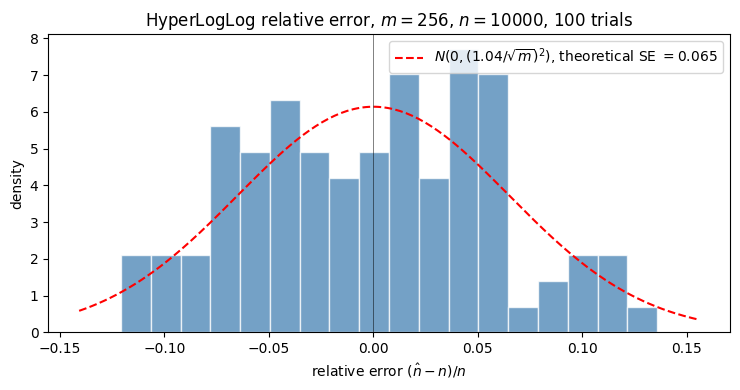

In [6]:
m_hll = 256
n_true = 10_000
trials_hll = 100
theoretical_rel_se = 1.04 / math.sqrt(m_hll)

errors = np.empty(trials_hll)
for t in range(trials_hll):
    hll = HyperLogLog(m=m_hll, seed=t)
    for i in range(n_true):
        hll.update(f"trial-{t}-item-{i}")
    est = hll.estimate()
    errors[t] = (est - n_true) / n_true

empirical_rel_se = float(np.sqrt(np.mean(errors ** 2)))
empirical_mean_err = float(np.mean(errors))

print(f"True cardinality n = {n_true}, registers m = {m_hll}")
print(f"Trials: {trials_hll}")
print()
print(f"Theoretical relative SE = 1.04 / sqrt(m) = {theoretical_rel_se:.4f}")
print(f"Empirical relative SE   = {empirical_rel_se:.4f}")
print(f"Empirical mean relative error (bias) = {empirical_mean_err:+.4f}")
print()
diff = abs(empirical_rel_se - theoretical_rel_se)
rel_diff = diff / theoretical_rel_se
print(f"|emp - theo| = {diff:.4f} ({100*rel_diff:.1f}% of theoretical)")
if rel_diff < 0.20:
    print("OK: empirical SE within 20% of theoretical (sampling fluctuation expected at 100 trials).")
else:
    print("WARN: empirical SE deviates noticeably from theoretical.")

# Histogram of relative errors with theoretical normal overlay.
fig, ax = plt.subplots(figsize=(7.5, 4.0))
ax.hist(errors, bins=18, density=True, color="steelblue", alpha=0.75, edgecolor="white")
xs = np.linspace(errors.min() - 0.02, errors.max() + 0.02, 200)
ax.plot(xs, stats.norm.pdf(xs, loc=0.0, scale=theoretical_rel_se), "r--",
        label=f"$N(0, (1.04/\\sqrt{{m}})^2)$, theoretical SE $= {theoretical_rel_se:.3f}$")
ax.axvline(0.0, color="k", lw=0.7, alpha=0.5)
ax.set_xlabel(r"relative error $(\hat{n} - n)/n$")
ax.set_ylabel("density")
ax.set_title(f"HyperLogLog relative error, $m={m_hll}$, $n={n_true}$, {trials_hll} trials")
ax.legend()
plt.tight_layout()
plt.show()

### 2.2 HyperLogLog Merge: Union of Two Streams

Two streams, each of cardinality 5000, with overlap of 1000 distinct items. The true union cardinality is $5000 + 5000 - 1000 = 9000$. Build two HyperLogLog sketches (same $m$, same seed for hash-family alignment), merge entry-wise via `np.maximum`, and check the merged estimate against the truth and against the standalone HyperLogLog of the union.

In [7]:
m_merge = 256
A_items = [f"u-{i}" for i in range(5000)]                     # 0..4999
B_items = [f"u-{i}" for i in range(4000, 9000)]               # 4000..8999, overlap 1000
union_items = sorted(set(A_items) | set(B_items))
true_union = len(union_items)

hll_A = HyperLogLog(m=m_merge, seed=0)
hll_B = HyperLogLog(m=m_merge, seed=0)
for x in A_items:
    hll_A.update(x)
for x in B_items:
    hll_B.update(x)

hll_merged = hll_A.merge(hll_B)

hll_direct = HyperLogLog(m=m_merge, seed=0)
for x in union_items:
    hll_direct.update(x)

n_hat_A = hll_A.estimate()
n_hat_B = hll_B.estimate()
n_hat_merge = hll_merged.estimate()
n_hat_direct = hll_direct.estimate()

rel_err_merge = (n_hat_merge - true_union) / true_union
theo_se = 1.04 / math.sqrt(m_merge)

print(f"True |A| = 5000, |B| = 5000, |A intersect B| = 1000, |A union B| = {true_union}")
print()
print(f"n_hat(A)           = {n_hat_A:>8.1f}")
print(f"n_hat(B)           = {n_hat_B:>8.1f}")
print(f"n_hat(merge(A,B))  = {n_hat_merge:>8.1f}")
print(f"n_hat(direct A U B)= {n_hat_direct:>8.1f}")
print()
print(f"Merged registers exactly equal direct-union registers: "
      f"{np.array_equal(hll_merged.registers, hll_direct.registers)}")
print(f"Merge relative error: {rel_err_merge:+.4f}; theoretical SE: {theo_se:.4f}")
if abs(rel_err_merge) < 3.0 * theo_se:
    print(f"OK: merge estimate within 3 theoretical SE ({3*theo_se:.4f}) of true union.")
else:
    print("WARN: merge estimate deviates by more than 3 theoretical SE.")

True |A| = 5000, |B| = 5000, |A intersect B| = 1000, |A union B| = 9000

n_hat(A)           =   4876.3
n_hat(B)           =   4929.9
n_hat(merge(A,B))  =   8676.2
n_hat(direct A U B)=   8676.2

Merged registers exactly equal direct-union registers: True
Merge relative error: -0.0360; theoretical SE: 0.0650
OK: merge estimate within 3 theoretical SE (0.1950) of true union.


## 3. MinHash: Approximate Jaccard Similarity

MinHash (Broder 1997; §10.4 `def:minhash`) estimates the Jaccard similarity $J(A, B) = |A \cap B| / |A \cup B|$ between two sets, using a signature of length $k$ per set.

**The trick.** For a hash $h$ uniform over a sufficiently large range, $\Pr[\min_{a \in A} h(a) = \min_{b \in B} h(b)] = J(A, B)$. Intuition: the argmin over $A \cup B$ is equally likely to be any element, so the chance the argmin lies in $A \cap B$ is $|A \cap B| / |A \cup B|$.

**Construction.** Pick $k$ independent hash functions $h_1, \ldots, h_k$ (here: SHA-256 with per-slot salt). The signature of $A$ is $\sigma(A) = (\min_{a \in A} h_1(a), \ldots, \min_{a \in A} h_k(a))$.

**Estimator.** $\hat{J}(A, B) = \frac{1}{k} \sum_{i=1}^k \mathbb{1}[\sigma_i(A) = \sigma_i(B)]$.

**Error bound (§10.4 `prop:minhash-error`).** $\hat{J}$ is the mean of $k$ Bernoulli($J$) trials, so $\Var[\hat{J}] = J(1-J)/k$ and Hoeffding gives $\Pr[|\hat{J} - J| \ge \epsilon] \le 2 e^{-2 k \epsilon^2}$.

In [8]:
class MinHash:
    """MinHash with k independent SHA256-based hash functions."""

    UINT64_MAX = (1 << 64) - 1

    def __init__(self, k, seed=0):
        self.k = int(k)
        self.seed = int(seed)
        self._salts = [
            hashlib.sha256(f"mh-{self.seed}-{i}".encode()).digest()
            for i in range(self.k)
        ]

    def _h64(self, i, item):
        digest = hashlib.sha256(self._salts[i] + str(item).encode()).digest()
        return int.from_bytes(digest[:8], "big")

    def signature(self, items):
        sig = np.full(self.k, self.UINT64_MAX, dtype=np.uint64)
        for x in items:
            for i in range(self.k):
                v = self._h64(i, x)
                if v < sig[i]:
                    sig[i] = v
        return sig

    @staticmethod
    def similarity(sig_a, sig_b):
        if sig_a.shape != sig_b.shape:
            raise ValueError("signatures must have the same length")
        return float(np.mean(sig_a == sig_b))

    def __repr__(self):
        return f"MinHash(k={self.k}, seed={self.seed})"


# Smoke test: identical set has J = 1; disjoint sets have J = 0.
mh_smoke = MinHash(k=64, seed=0)
sig_X = mh_smoke.signature(["a", "b", "c", "d"])
sig_X2 = mh_smoke.signature(["d", "c", "b", "a"])
sig_Y = mh_smoke.signature(["e", "f", "g", "h"])
print("J_hat(X, X')  =", MinHash.similarity(sig_X, sig_X2), "(true 1.0)")
print("J_hat(X, Y)   =", MinHash.similarity(sig_X, sig_Y),  "(true 0.0)")

J_hat(X, X')  = 1.0 (true 1.0)
J_hat(X, Y)   = 0.0 (true 0.0)


### 3.1 MinHash Accuracy: $J = 30/170 \approx 0.176$, $k = 200$

Two sets of size 100 with overlap 30: $|A| = |B| = 100$, $|A \cap B| = 30$, $|A \cup B| = 170$, $J = 30/170 \approx 0.1765$.

With $k = 200$, the standard error from $\Var[\hat{J}] = J(1-J)/k$ is $\sqrt{0.176 \cdot 0.824 / 200} \approx 0.027$. A single trial should land within $\pm 0.05$ of $J$ with very high probability (about $\pm 1.85 \sigma$).

Also report a 20-trial empirical distribution to confirm the $0.027$ standard-error prediction.

In [9]:
k_mh = 200
overlap = [f"common-{i}" for i in range(30)]
A_set = overlap + [f"a-only-{i}" for i in range(70)]
B_set = overlap + [f"b-only-{i}" for i in range(70)]
true_J = len(set(A_set) & set(B_set)) / len(set(A_set) | set(B_set))
theo_se_J = math.sqrt(true_J * (1.0 - true_J) / k_mh)

print(f"|A| = {len(A_set)}, |B| = {len(B_set)}, |A intersect B| = {len(set(A_set) & set(B_set))}")
print(f"|A union B| = {len(set(A_set) | set(B_set))}")
print(f"True J = {true_J:.4f}")
print(f"Theoretical SE = sqrt(J(1-J)/k) = {theo_se_J:.4f} (with k = {k_mh})")
print()

mh = MinHash(k=k_mh, seed=0)
sig_A = mh.signature(A_set)
sig_B = mh.signature(B_set)
J_hat = MinHash.similarity(sig_A, sig_B)
print(f"Single-trial estimate J_hat = {J_hat:.4f}")
print(f"|J_hat - J| = {abs(J_hat - true_J):.4f}  (target < 0.05)")
assert abs(J_hat - true_J) < 0.05, "single-trial estimate fell outside +/- 0.05 of true J"
print("OK: single-trial estimate within +/- 0.05 of true J.")
print()

# Empirical distribution over 20 independent sketches (different hash families).
n_trials_mh = 20
estimates = []
for t in range(n_trials_mh):
    mh_t = MinHash(k=k_mh, seed=t + 100)
    estimates.append(MinHash.similarity(mh_t.signature(A_set), mh_t.signature(B_set)))
estimates = np.array(estimates)
print(f"{n_trials_mh}-trial estimates:")
print(f"  mean = {estimates.mean():.4f}  (true J = {true_J:.4f})")
print(f"  empirical SE = {estimates.std(ddof=1):.4f}  (theoretical = {theo_se_J:.4f})")
print(f"  min / max    = {estimates.min():.4f} / {estimates.max():.4f}")

|A| = 100, |B| = 100, |A intersect B| = 30
|A union B| = 170
True J = 0.1765
Theoretical SE = sqrt(J(1-J)/k) = 0.0270 (with k = 200)

Single-trial estimate J_hat = 0.1650
|J_hat - J| = 0.0115  (target < 0.05)
OK: single-trial estimate within +/- 0.05 of true J.



20-trial estimates:
  mean = 0.1762  (true J = 0.1765)
  empirical SE = 0.0203  (theoretical = 0.0270)
  min / max    = 0.1300 / 0.2050


## 4. Three-Sketch Storage and Accuracy Summary

Take a common scenario for comparison:
- **CountMin:** $w = 272$, $d = 7$ (matching §1.2); each cell a 64-bit counter.
- **HyperLogLog:** $m = 256$; each register a 6-bit field in production (an `int8` here, but the information-theoretic content is 6 bits per register for cardinalities up to $2^{64}$).
- **MinHash:** $k = 200$; each signature slot a 64-bit hash.

Storage cost reports bits per sketch (the structural size, not the implementation overhead) and the accuracy guarantee in the units native to each sketch (per-query failure probability for CountMin, relative SE for HyperLogLog, additive SE for MinHash).

In [10]:
# Per-sketch storage cost (bits) and accuracy guarantee on the scenarios above.
cm_w, cm_d = 272, 7
cm_bits_per_cell = 64                      # int64 counters in this implementation
cm_storage = cm_w * cm_d * cm_bits_per_cell

hll_m = 256
hll_bits_per_register = 6                  # production-relevant; the int8 here is a Python convenience
hll_storage = hll_m * hll_bits_per_register
hll_rel_se = 1.04 / math.sqrt(hll_m)

mh_k = 200
mh_bits_per_slot = 64
mh_storage = mh_k * mh_bits_per_slot
mh_J_ref = 30.0 / 170.0
mh_se_at_ref = math.sqrt(mh_J_ref * (1.0 - mh_J_ref) / mh_k)

rows = [
    ("CountMin",     f"w={cm_w}, d={cm_d}",      cm_storage,
     "frequency (N)",
     "one-sided over-est",
     f"per-query failure rate < {delta} at eps F = {threshold:.0f}"),
    ("HyperLogLog",  f"m={hll_m}",                hll_storage,
     "cardinality (N)",
     "two-sided, approx. log-normal",
     f"relative SE approx. {hll_rel_se:.4f}"),
    ("MinHash",      f"k={mh_k}",                 mh_storage,
     "similarity ([0, 1])",
     "two-sided, binomial",
     f"SE approx. {mh_se_at_ref:.4f} at J = {mh_J_ref:.3f}"),
]

header = ("sketch", "params", "bits", "T (output)", "error structure", "accuracy guarantee")
widths = [12, 16, 8, 22, 30, 48]
fmt = "  ".join(f"{{:<{w}s}}" for w in widths)
print(fmt.format(*header))
print("  ".join("-" * w for w in widths))
for sketch, params, bits, T, struct, acc in rows:
    print(fmt.format(sketch, params, f"{bits:,}", T, struct, acc))

print()
print("Bits-per-distinct-item efficiency (HyperLogLog only, n = 10000):")
print(f"  HLL storage = {hll_storage} bits for n_hat of n = 10000")
print(f"  bits / log2(n) = {hll_storage / math.log2(10_000):.2f} (compare info-theoretic floor)")

sketch        params            bits      T (output)              error structure                 accuracy guarantee                              
------------  ----------------  --------  ----------------------  ------------------------------  ------------------------------------------------
CountMin      w=272, d=7        121,856   frequency (N)           one-sided over-est              per-query failure rate < 0.001 at eps F = 100   
HyperLogLog   m=256             1,536     cardinality (N)         two-sided, approx. log-normal   relative SE approx. 0.0650                      
MinHash       k=200             12,800    similarity ([0, 1])     two-sided, binomial             SE approx. 0.0270 at J = 0.176                  

Bits-per-distinct-item efficiency (HyperLogLog only, n = 10000):
  HLL storage = 1536 bits for n_hat of n = 10000
  bits / log2(n) = 115.60 (compare info-theoretic floor)


## 5. Discussion: Three Sketches, Three $\Bernoulli{T}$ Instances

Each sketch in this notebook is an instance of the $\Bernoulli{T}$ type family from chapter 9:

- **CountMin** is $\Bernoulli{\mathbb{N}}$. The output type $T$ is a non-negative integer (a count). The channel matrix $Q$ has rows indexed by the true frequency $f_a$ and columns by the reported $\hat{f}_a$. Structure: $Q_{f, \hat{f}} = 0$ for $\hat{f} < f$ (the one-sided property of §1) and a geometric-like tail above. The error parameters $(\epsilon, \delta)$ pin down two summary statistics of $Q$: the per-row failure probability above the threshold $f + \epsilon F$.
- **HyperLogLog** is also $\Bernoulli{\mathbb{N}}$ but with a two-sided $Q$. Rows are indexed by true cardinality $n$, columns by $\hat{n}$. The marginal $Q_{n, \cdot}$ is approximately log-normal with relative standard deviation $1.04 / \sqrt{m}$; the structure is induced by the max-of-leading-zeros estimator over $m$ buckets.
- **MinHash** is $\Bernoulli{[0, 1]}$. Rows are indexed by true Jaccard $J$, columns by $\hat{J}$. Each $Q$-row is a scaled Binomial: $k \hat{J} \sim \Binomial(k, J)$. The variance $J(1-J)/k$ collapses smoothly with $k$.

**What chapter 13 unifies.** Each sketch comes with a merge operation: entry-wise add (CountMin), entry-wise max (HyperLogLog), or a join over signatures (MinHash via shared hash family). Chapter 9 §9.3 (`thm:n-ary-kronecker`) gives the joint-distribution factorization for $m$ independent queries on the same sketch. Chapter 13 takes the next step: a single type-algebra under which the three merge operations are instances of a common pattern (a monoid on the sketch state induced by the underlying $T$ and the channel structure). Once that algebra is in place, composition is by structure, not by case analysis per sketch.

**What this notebook verified:**

| Section | Claim | Verified |
|---------|-------|----------|
| §1 `thm:countmin-bound` | $w = \lceil e/\epsilon \rceil, d = \lceil \ln(1/\delta) \rceil$ delivers per-query failure rate $< \delta$ | yes (100 trials at $\epsilon = 0.01, \delta = 0.001$) |
| §1 one-sided | $\hat{f}_a \ge f_a$ for every item | yes (Zipfian-tail stream) |
| §2 `prop:hyperloglog-error` | Relative SE $\approx 1.04 / \sqrt{m}$ | yes (100 trials at $m = 256, n = 10000$) |
| §2 merge | Entry-wise max recovers the HLL of the union | yes (registers bit-identical to direct-union HLL) |
| §3 `prop:minhash-error` | $\Var[\hat{J}] = J(1-J)/k$ | yes (20-trial empirical SE matches theory at $J = 0.176, k = 200$) |